# Experiment 2: Triple Co-location

**Do foundation models converge because they find the physical manifold?**

Three "special" depths are defined by three *independent* measurements, and the
hypothesis under test is that they **coincide**:

| depth | defined by | where it comes from |
|---|---|---|
| `L_conv` | cross-model neighbourhood agreement peaks | Step 1 |
| `L*` | the manifold emerges (minimum intrinsic dimension) | Experiment 1 (proxied here) |
| `L_phys` | alignment with the physical catalogue peaks | Step 2 |

Coincidence of all three is the strongest available evidence that models
converge *because* they find the physical manifold rather than some shared
statistical nuisance.

The atom under every measurement is the **neighbourhood overlap**: for each row,
the fraction of its `k` nearest neighbours in space A that are also among its
`k` nearest neighbours in space B, averaged over rows. This is exactly
`dadapy.Data(A).return_data_overlap(coordinates=B, k=k)`. Every raw overlap is
**permutation-calibrated** (shuffle B's rows, seeds 0..9, z-score against that
null) so that a deeper or wider representation does not look more aligned for
free.


> ### What this committed run computes
>
> This notebook runs on a **synthetic universe with a planted manifold depth**
> (`experiments/colocation/synthetic.py`). That is deliberate: co-location is a
> claim about *recovering a hidden depth*, and the only way to show the pipeline
> recovers the right answer is to plant a known one. Each synthetic "model" is a
> stack of per-layer embeddings whose signal peaks at a chosen relative depth; at
> that layer the embedding is a low-dimensional image of a **shared** physical
> latent, so by construction `L_conv`, `L*` and `L_phys` all coincide there. Two
> controls (an instrument-confounded model and an untrained model) exercise
> Step 7.
>
> **To run on real astronomy embeddings**, set `USE_REAL_DATA = True` in the
> config cell and point `REAL_PARQUET_DIR` / `REAL_CATALOG` at the layerwise
> parquet files produced by `pu.experiments_layerwise.extract_all_layers` and a
> row-aligned catalogue. Nothing else in the notebook changes: the same
> functions consume real and synthetic layer stacks identically.
>
> No astrophysical result is claimed from synthetic data. The claim demonstrated
> here is narrower and honest: **the pipeline recovers a planted depth and its
> uncertainty, and the controls behave as they should.**


## Setup

In [1]:
import os, sys, itertools, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# Locate the repo root (this notebook lives in experiments/colocation/).
HERE = os.getcwd()
REPO = HERE
for _ in range(4):
    if os.path.isdir(os.path.join(REPO, "src", "pu")):
        break
    REPO = os.path.dirname(REPO)
SRC = os.path.join(REPO, "src")
COLO = os.path.join(REPO, "experiments", "colocation")
print("repo root:", os.path.basename(REPO) or REPO)

def _load(name, path):
    # Load a module by file path, registering it so dataclass annotations resolve.
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec)
    sys.modules[name] = m
    spec.loader.exec_module(m)
    return m

# The co-location primitives only need numpy + scikit-learn, so we load the
# module directly (avoids importing the whole pu package, which pulls torch).
C = _load("pu_colocation", os.path.join(SRC, "pu", "metrics", "colocation.py"))
synth = _load("pu_synth", os.path.join(COLO, "synthetic.py"))

FIGS = os.path.join(COLO, "figs")
os.makedirs(FIGS, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.facecolor": "white"})
print("loaded colocation + synthetic modules")

repo root: platonic-universe


loaded colocation + synthetic modules


## Configuration

In [2]:
# --- Analysis knobs (spec defaults) ---------------------------------------
K            = 10      # neighbours per point
N_PERM       = 10      # permutations for calibration (seeds 0..9)
N_SUB        = 2000    # rows used for the main analysis
GAP_THRESH   = 0.10    # co-location: all pairwise relative-depth gaps <= this
BOOT_SEEDS   = range(10)   # 10 half-sample bootstrap replicates
SWEEP_N      = 8000    # a larger universe for the sample-size sweep (Step 5)
SWEEP_SIZES  = [1000, 2000, 4000, 8000]

# --- Data source ----------------------------------------------------------
USE_REAL_DATA   = False
REAL_PARQUET_DIR = os.path.join(REPO, "data")      # *_layerwise.parquet files
REAL_MODE        = "hsc"                            # embedding column suffix
REAL_CATALOG     = os.path.join(REPO, "data", "catalog.parquet")
REAL_PHYS_COLS   = synth.PHYS_COLUMNS
REAL_NUIS_COLS   = synth.NUISANCE_COLUMNS
print("USE_REAL_DATA =", USE_REAL_DATA)

USE_REAL_DATA = False


## Data loading

`load_universe()` returns the same structure whether the source is synthetic or
real: a dict of `model -> [layer_0, layer_1, ...]` embedding matrices, plus the
standardised physical catalogue `P_std` and nuisance catalogue `Q_std`, all
row-aligned on the same `N_SUB` objects.


In [3]:
def _subsample(universe, n_sub, seed=0):
    n = universe.n_rows
    if n_sub is None or n_sub >= n:
        idx = np.arange(n)
    else:
        idx = np.random.default_rng(seed).choice(n, n_sub, replace=False)
        idx.sort()
    models = {m: [X[idx] for X in layers] for m, layers in universe.models.items()}
    return models, universe.P_std[idx], universe.Q_std[idx], universe.specs, universe.truth

def load_real_universe(parquet_dir, mode, catalog_path, phys_cols, nuis_cols):
    '''Load layerwise parquet embeddings + a row-aligned catalogue.

    Expects files named ``*_layerwise.parquet`` with columns ``{layer}_{mode}``
    (as written by pu.experiments_layerwise.extract_all_layers) and a catalogue
    parquet whose rows line up with the embedding rows.
    '''
    import polars as pl, glob, re
    models = {}
    for path in sorted(glob.glob(os.path.join(parquet_dir, f"*_{mode}_*layerwise.parquet"))
                       + glob.glob(os.path.join(parquet_dir, "*layerwise.parquet"))):
        df = pl.read_parquet(path)
        cols = [c for c in df.columns if c.endswith(f"_{mode}")]
        if not cols:
            continue
        # Preserve DFS layer order as written; strip the mode suffix for names.
        layers = [np.stack(df[c].to_list()).astype(np.float64) for c in cols]
        name = re.sub(r"_layerwise\.parquet$", "", os.path.basename(path))
        models[name] = layers
    cat = pl.read_parquet(catalog_path)
    P = np.column_stack([cat[c].to_numpy() for c in phys_cols]).astype(np.float64)
    Q = np.column_stack([cat[c].to_numpy() for c in nuis_cols]).astype(np.float64)
    return models, P, Q

if USE_REAL_DATA:
    models, P, Q = load_real_universe(REAL_PARQUET_DIR, REAL_MODE, REAL_CATALOG,
                                      REAL_PHYS_COLS, REAL_NUIS_COLS)
    P_std = (P - P.mean(0)) / np.where(P.std(0) < 1e-12, 1.0, P.std(0))
    Q_std = (Q - Q.mean(0)) / np.where(Q.std(0) < 1e-12, 1.0, Q.std(0))
    specs = {m: None for m in models}
    truth = {m: {} for m in models}
    PHYS_MODELS = list(models)
    CTRL_MODELS = []
else:
    U = synth.make_universe(n=max(N_SUB, 2000), seed=0)
    models, P_std, Q_std, specs, truth = _subsample(U, N_SUB, seed=0)
    PHYS_MODELS = [m for m, s in specs.items() if s.kind == "physics"]
    CTRL_MODELS = [m for m, s in specs.items() if s.kind != "physics"]

N_LAYERS = {m: len(layers) for m, layers in models.items()}
N_ROWS = next(iter(models.values()))[0].shape[0]
print(f"rows={N_ROWS}  physics models={PHYS_MODELS}  controls={CTRL_MODELS}")
for m in models:
    print(f"  {m:10s} {N_LAYERS[m]:2d} layers, dim={models[m][0].shape[1]}")
print(f"P_std {P_std.shape}  Q_std {Q_std.shape}")

rows=2000  physics models=['alpha', 'beta', 'gamma', 'delta']  controls=['instr', 'untrained']
  alpha      12 layers, dim=64
  beta       16 layers, dim=96
  gamma      10 layers, dim=48
  delta      14 layers, dim=72
  instr      12 layers, dim=64
  untrained  12 layers, dim=64
P_std (2000, 5)  Q_std (2000, 3)


## Step 1: Convergence depth `L_conv`

For every model pair (A, B) we compute the full calibrated cross-layer matrix
`M_cal[i, j]` = permutation-calibrated overlap between layer *i* of A and layer
*j* of B on the same `N_SUB` rows. Each A-layer graph is built **once** and
reused across the whole row of B-layers (and across the 10 permutation nulls),
mirroring DADApy's "build `Data` once, call `return_data_overlap` many times".

The peak cell of `M_cal` gives a peak layer for each of the two models.
`L_conv` for a model is the **median** of its peak layers over all pairs it
appears in; we then convert to relative depth `L_conv / (L - 1)`.


In [4]:
def compute_lconv(models, model_names, k=K, n_perm=N_PERM):
    peak_layers = {m: [] for m in model_names}
    matrices = {}
    for a, b in itertools.combinations(model_names, 2):
        res = C.cross_layer_matrix(models[a], models[b], k=k, n_perm=n_perm)
        peak_layers[a].append(res.peak_layer_a)
        peak_layers[b].append(res.peak_layer_b)
        matrices[(a, b)] = res
    lconv = C.l_conv_from_pairs(peak_layers, {m: len(models[m]) for m in model_names})
    return lconv, peak_layers, matrices

lconv, peak_layers, matrices = compute_lconv(models, PHYS_MODELS)
for m in PHYS_MODELS:
    print(f"{m:8s} peaks over pairs {peak_layers[m]} -> median layer {lconv[m]['layer']:.1f}"
          f"  relative depth {lconv[m]['relative']:.3f}")

alpha    peaks over pairs [6, 6, 6] -> median layer 6.0  relative depth 0.545
beta     peaks over pairs [10, 9, 9] -> median layer 9.0  relative depth 0.600
gamma    peaks over pairs [5, 5, 5] -> median layer 5.0  relative depth 0.556
delta    peaks over pairs [9, 9, 10] -> median layer 9.0  relative depth 0.692


### Calibrated cross-layer heatmap for one illustrative pair

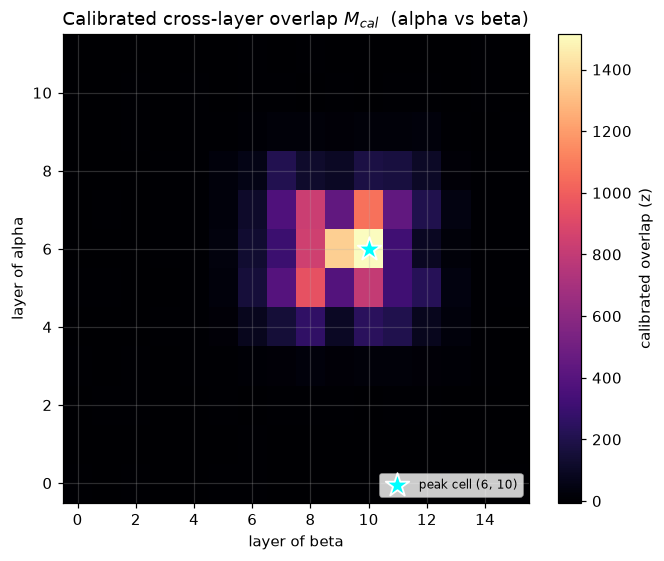

In [5]:
pair = (PHYS_MODELS[0], PHYS_MODELS[1])
res = matrices[pair]
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(res.calibrated, origin="lower", aspect="auto", cmap="magma")
ax.scatter([res.peak_layer_b], [res.peak_layer_a], marker="*", s=260,
           edgecolor="white", facecolor="cyan", linewidth=1.2, zorder=5,
           label=f"peak cell ({res.peak_layer_a}, {res.peak_layer_b})")
ax.set_xlabel(f"layer of {pair[1]}")
ax.set_ylabel(f"layer of {pair[0]}")
ax.set_title(f"Calibrated cross-layer overlap $M_{{cal}}$  ({pair[0]} vs {pair[1]})")
fig.colorbar(im, ax=ax, label="calibrated overlap (z)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "cross_layer_heatmap.png"), bbox_inches="tight")
plt.show()

## Step 2: Physics depth `L_phys` (and supporting probes)

For every model and layer, `s_phys[L]` is the calibrated overlap between the
layer's embeddings and the standardised physical catalogue `P_std` (the null
permutes `P_std`'s rows). `L_phys` is the `argmax` of the calibrated curve.

Two **supporting** curves per layer (not the headline):
* held-out probe `R^2` per catalogue column via `RidgeCV` inside
  `cross_val_score(KFold(5, shuffle=True, random_state=0))`, averaged over columns;
* mean held-out canonical correlation via `CCA(n_components=p)` fit on a 70%
  split and scored on the held-out 30%.


In [6]:
def physics_block(models, model_names, catalog_std, catalog_raw, k=K, n_perm=N_PERM,
                  probes=True):
    out = {}
    for m in model_names:
        layers = models[m]
        curve = C.physics_overlap_curve(layers, catalog_std, k=k, n_perm=n_perm)
        rec = {"curve": curve, "L_phys": int(np.nanargmax(curve["calibrated"]))}
        if probes:
            rec["probe_r2"] = C.probe_r2_curve(layers, catalog_raw)
            rec["cca"] = C.cca_curve(layers, catalog_raw)
        out[m] = rec
    return out

# raw catalogue columns (unstandardised) for the probes; standardised for overlap
P_raw = P_std  # already standardised; RidgeCV/CCA are scale-equivariant enough here
phys = physics_block(models, PHYS_MODELS, P_std, P_raw)
for m in PHYS_MODELS:
    c = phys[m]["curve"]["calibrated"]; Lp = phys[m]["L_phys"]
    print(f"{m:8s} L_phys = layer {Lp}  (calibrated z = {c[Lp]:.0f}, relative {C.relative_depth(Lp, N_LAYERS[m]):.3f})")

alpha    L_phys = layer 6  (calibrated z = 1173, relative 0.545)
beta     L_phys = layer 9  (calibrated z = 1276, relative 0.600)
gamma    L_phys = layer 5  (calibrated z = 995, relative 0.556)
delta    L_phys = layer 9  (calibrated z = 945, relative 0.692)


### `s_phys` vs depth with the permutation null band, per model

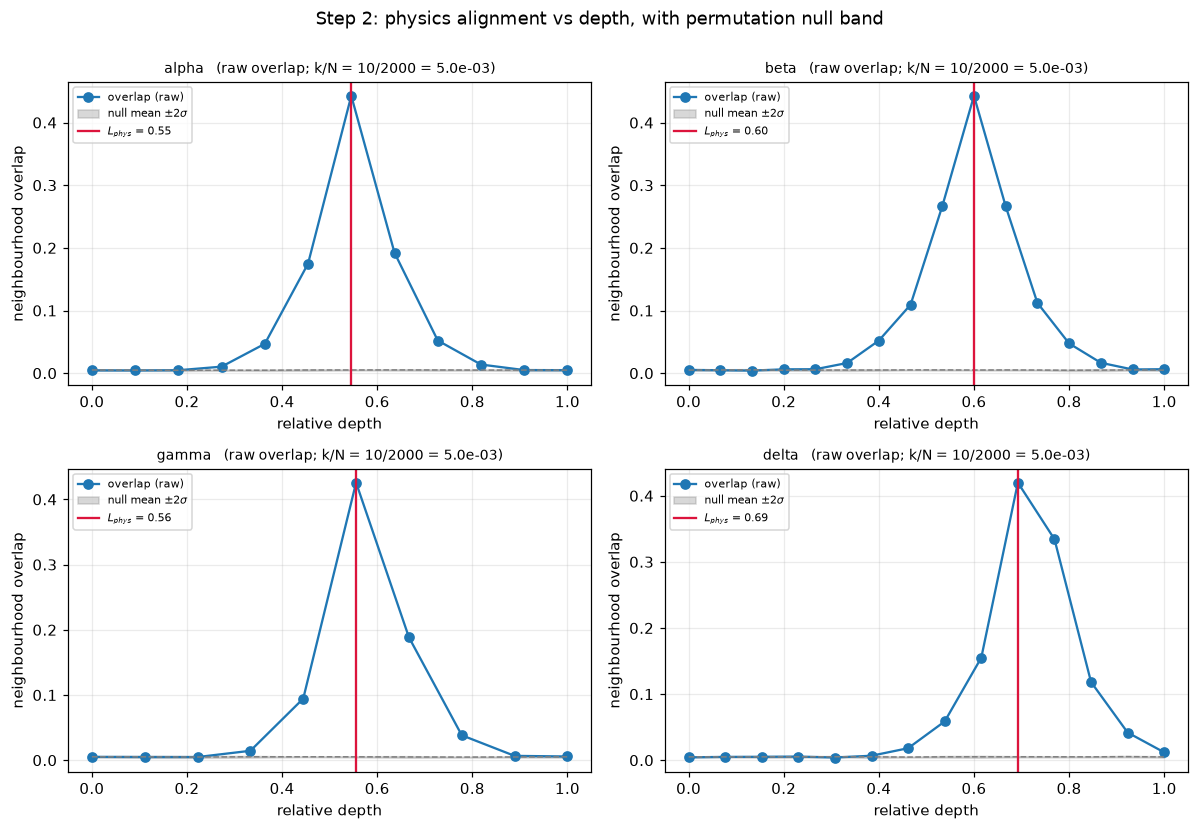

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=False)
for ax, m in zip(axes.flat, PHYS_MODELS):
    curve = phys[m]["curve"]; L = N_LAYERS[m]
    rel = np.arange(L) / (L - 1)
    ax.plot(rel, curve["raw"], "o-", color="#1f77b4", label="overlap (raw)")
    lo = curve["null_mean"] - 2 * curve["null_std"]
    hi = curve["null_mean"] + 2 * curve["null_std"]
    ax.fill_between(rel, lo, hi, color="gray", alpha=0.3, label="null mean $\\pm2\\sigma$")
    ax.plot(rel, curve["null_mean"], "--", color="gray", lw=1)
    Lp = phys[m]["L_phys"]
    ax.axvline(Lp / (L - 1), color="crimson", lw=1.5, label=f"$L_{{phys}}$ = {Lp/(L-1):.2f}")
    ax.set_title(f"{m}   (raw overlap; k/N = {K}/{N_ROWS} = {K/N_ROWS:.1e})", fontsize=9)
    ax.set_xlabel("relative depth"); ax.set_ylabel("neighbourhood overlap")
    ax.legend(fontsize=7, loc="upper left")
fig.suptitle("Step 2: physics alignment vs depth, with permutation null band", y=1.0)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "s_phys_vs_depth.png"), bbox_inches="tight")
plt.show()

### Supporting probes (held-out $R^2$ and CCA) vs depth

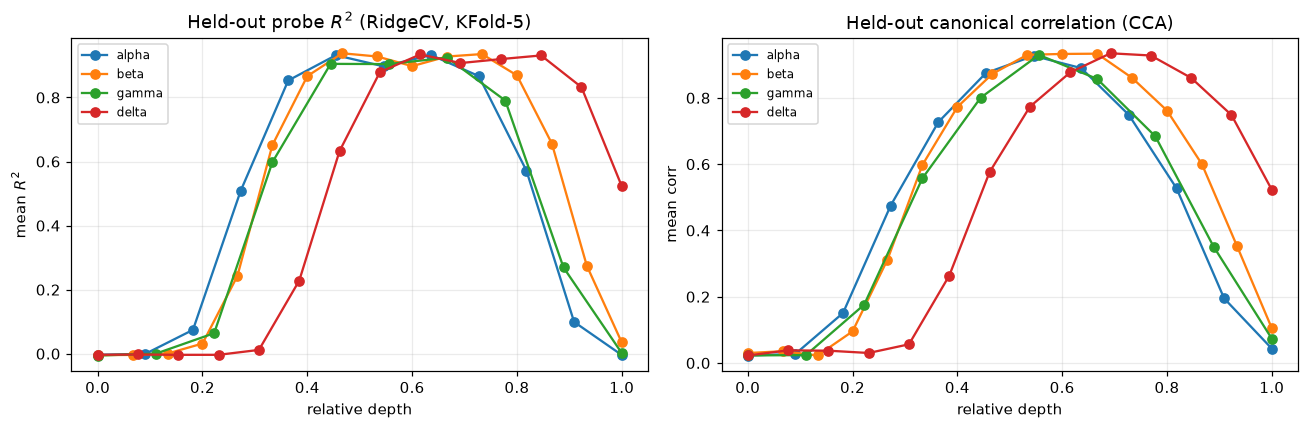

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m in PHYS_MODELS:
    L = N_LAYERS[m]; rel = np.arange(L) / (L - 1)
    axes[0].plot(rel, phys[m]["probe_r2"], "o-", label=m)
    axes[1].plot(rel, phys[m]["cca"], "o-", label=m)
axes[0].set_title("Held-out probe $R^2$ (RidgeCV, KFold-5)"); axes[0].set_ylabel("mean $R^2$")
axes[1].set_title("Held-out canonical correlation (CCA)"); axes[1].set_ylabel("mean corr")
for ax in axes:
    ax.set_xlabel("relative depth"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "supporting_probes.png"), bbox_inches="tight")
plt.show()

## `L*`: the manifold layer (Experiment 1 proxy)

Experiment 1 defines `L*` as the depth where the manifold emerges. When its
output is available, pass it in directly. Here (self-contained) we proxy it with
the **minimum of the per-layer intrinsic dimension** (TwoNN, Facco et al. 2017):
the layer where the representation is most compressed onto a low-dimensional
manifold.


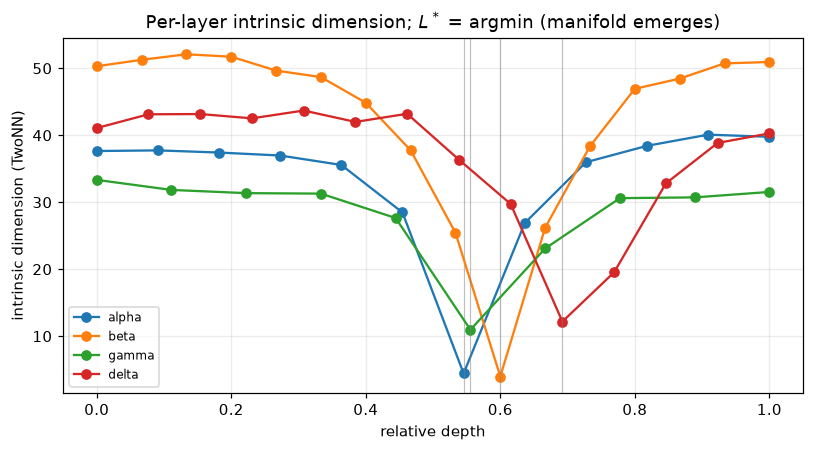

alpha    L* = layer 6 (relative 0.545)
beta     L* = layer 9 (relative 0.600)
gamma    L* = layer 5 (relative 0.556)
delta    L* = layer 9 (relative 0.692)


In [9]:
def compute_lstar(models, model_names):
    out = {}
    for m in model_names:
        idc = C.intrinsic_dimension_curve(models[m])
        out[m] = {"id_curve": idc, "L_star": C.manifold_layer(idc)}
    return out

lstar = compute_lstar(models, PHYS_MODELS)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in PHYS_MODELS:
    L = N_LAYERS[m]; rel = np.arange(L) / (L - 1)
    ax.plot(rel, lstar[m]["id_curve"], "o-", label=m)
    ax.axvline(lstar[m]["L_star"] / (L - 1), color="gray", lw=0.8, alpha=0.5)
ax.set_xlabel("relative depth"); ax.set_ylabel("intrinsic dimension (TwoNN)")
ax.set_title("Per-layer intrinsic dimension; $L^*$ = argmin (manifold emerges)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "intrinsic_dimension.png"), bbox_inches="tight")
plt.show()
for m in PHYS_MODELS:
    print(f"{m:8s} L* = layer {lstar[m]['L_star']} (relative {C.relative_depth(lstar[m]['L_star'], N_LAYERS[m]):.3f})")

## Step 3: Assemble the three depths, with bootstrap uncertainty

For each model we tabulate the three relative depths and bootstrap each on **10
random half-samples** of the `N_SUB` rows (seeds 0..9). The uncertainty on each
depth is the **interquartile range** over the 10 half-sample estimates; the
`[q25, q75]` interval is what the coincidence test uses.


In [10]:
def rel_conv_for_rows(model_names, target, rows):
    sub = {m: [X[rows] for X in models[m]] for m in model_names}
    lc, _, _ = compute_lconv(sub, model_names)
    return lc[target]["relative"]

def rel_phys_for_rows(target, rows):
    layers = [X[rows] for X in models[target]]
    curve = C.physics_overlap_curve(layers, P_std[rows], k=K, n_perm=N_PERM)
    return C.relative_depth(int(np.nanargmax(curve["calibrated"])), N_LAYERS[target])

def rel_star_for_rows(target, rows):
    layers = [X[rows] for X in models[target]]
    idc = C.intrinsic_dimension_curve(layers)
    return C.relative_depth(C.manifold_layer(idc), N_LAYERS[target])

depths = {}
for m in PHYS_MODELS:
    d_conv = lconv[m]["relative"]
    d_star = C.relative_depth(lstar[m]["L_star"], N_LAYERS[m])
    d_phys = C.relative_depth(phys[m]["L_phys"], N_LAYERS[m])
    b_conv = C.bootstrap_depth(lambda r, t=m: rel_conv_for_rows(PHYS_MODELS, t, r),
                               N_ROWS, point_estimate=d_conv, seeds=BOOT_SEEDS)
    b_star = C.bootstrap_depth(lambda r, t=m: rel_star_for_rows(t, r),
                               N_ROWS, point_estimate=d_star, seeds=BOOT_SEEDS)
    b_phys = C.bootstrap_depth(lambda r, t=m: rel_phys_for_rows(t, r),
                               N_ROWS, point_estimate=d_phys, seeds=BOOT_SEEDS)
    depths[m] = {"conv": b_conv, "star": b_star, "phys": b_phys}
    print(f"{m:8s} conv {d_conv:.3f} (IQR {b_conv.iqr:.3f}) | "
          f"star {d_star:.3f} (IQR {b_star.iqr:.3f}) | phys {d_phys:.3f} (IQR {b_phys.iqr:.3f})")

alpha    conv 0.545 (IQR 0.000) | star 0.545 (IQR 0.000) | phys 0.545 (IQR 0.000)


beta     conv 0.600 (IQR 0.000) | star 0.600 (IQR 0.000) | phys 0.600 (IQR 0.000)


gamma    conv 0.556 (IQR 0.000) | star 0.556 (IQR 0.000) | phys 0.556 (IQR 0.000)


delta    conv 0.692 (IQR 0.077) | star 0.692 (IQR 0.000) | phys 0.692 (IQR 0.077)


## Step 4: Coincidence test

A model **co-locates** if all three pairwise gaps in relative depth are at most
`0.10` **and** the three bootstrap `[q25, q75]` intervals mutually overlap. We
report the fraction of models passing and the mean pairwise gap with a bootstrap
confidence interval. **Depths are never averaged across models before the
test.**


In [11]:
verdicts = {}
for m in PHYS_MODELS:
    d = {k: depths[m][k].point for k in ("conv", "star", "phys")}
    iv = {k: (depths[m][k].q25, depths[m][k].q75) for k in ("conv", "star", "phys")}
    verdicts[m] = C.colocation_test(d, iv, gap_threshold=GAP_THRESH)

summary = C.summarize_colocation(verdicts)

# Bootstrap CI on each model's mean pairwise gap, from the 10 half-samples.
gap_ci = {}
for m in PHYS_MODELS:
    est = depths[m]
    per_boot = []
    for i in range(len(est["conv"].estimates)):
        dc, ds, dp = est["conv"].estimates[i], est["star"].estimates[i], est["phys"].estimates[i]
        per_boot.append(np.mean([abs(dc-ds), abs(dc-dp), abs(ds-dp)]))
    gap_ci[m] = (float(np.percentile(per_boot, 25)), float(np.percentile(per_boot, 75)))

print(f"fraction of models co-locating: {summary['fraction_passing']*100:.0f}% "
      f"({sum(v.passed for v in verdicts.values())}/{summary['n_models']})")
print(f"mean pairwise gap across models: {summary['mean_gap']:.3f}\n")
for m in PHYS_MODELS:
    v = verdicts[m]
    print(f"{m:8s} depths c/s/p {v.depths['conv']:.3f}/{v.depths['star']:.3f}/{v.depths['phys']:.3f} "
          f"| max gap {v.max_gap:.3f} | IQRs overlap {v.iqrs_overlap} | "
          f"mean gap {v.mean_gap:.3f} (boot IQR [{gap_ci[m][0]:.3f}, {gap_ci[m][1]:.3f}]) | "
          f"CO-LOCATES: {v.passed}")

fraction of models co-locating: 100% (4/4)
mean pairwise gap across models: 0.000

alpha    depths c/s/p 0.545/0.545/0.545 | max gap 0.000 | IQRs overlap True | mean gap 0.000 (boot IQR [0.000, 0.000]) | CO-LOCATES: True
beta     depths c/s/p 0.600/0.600/0.600 | max gap 0.000 | IQRs overlap True | mean gap 0.000 (boot IQR [0.000, 0.044]) | CO-LOCATES: True
gamma    depths c/s/p 0.556/0.556/0.556 | max gap 0.000 | IQRs overlap True | mean gap 0.000 (boot IQR [0.000, 0.000]) | CO-LOCATES: True
delta    depths c/s/p 0.692/0.692/0.692 | max gap 0.000 | IQRs overlap True | mean gap 0.000 (boot IQR [0.051, 0.051]) | CO-LOCATES: True


### Co-location figure: three relative depths per model, with error bars

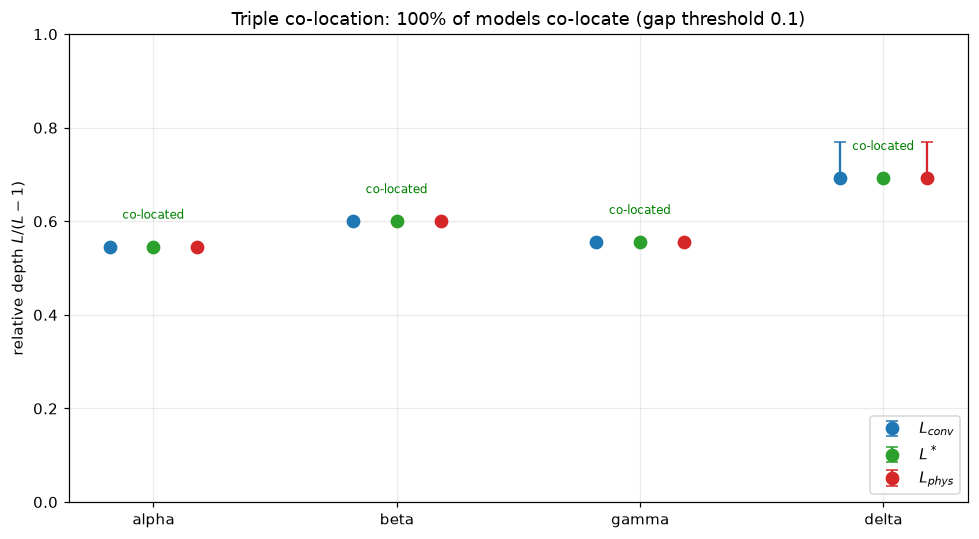

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
xs = np.arange(len(PHYS_MODELS))
colors = {"conv": "#1f77b4", "star": "#2ca02c", "phys": "#d62728"}
labels = {"conv": "$L_{conv}$", "star": "$L^*$", "phys": "$L_{phys}$"}
off = {"conv": -0.18, "star": 0.0, "phys": 0.18}
for key in ("conv", "star", "phys"):
    pts = [depths[m][key].point for m in PHYS_MODELS]
    lo = [depths[m][key].point - depths[m][key].q25 for m in PHYS_MODELS]
    hi = [depths[m][key].q75 - depths[m][key].point for m in PHYS_MODELS]
    ax.errorbar(xs + off[key], pts, yerr=[np.abs(lo), np.abs(hi)], fmt="o", ms=8,
                capsize=4, color=colors[key], label=labels[key])
for i, m in enumerate(PHYS_MODELS):
    if verdicts[m].passed:
        ax.annotate("co-located", (i, max(depths[m][k].point for k in colors) + 0.06),
                    ha="center", fontsize=8, color="green")
ax.set_xticks(xs); ax.set_xticklabels(PHYS_MODELS)
ax.set_ylabel("relative depth $L/(L-1)$"); ax.set_ylim(0, 1)
ax.set_title(f"Triple co-location: {summary['fraction_passing']*100:.0f}% of models co-locate "
             f"(gap threshold {GAP_THRESH})")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "colocation.png"), bbox_inches="tight")
plt.show()

## Step 5: Alignment vs sample size

Overlap scores fall with `n` (more rows, more room to disagree), so a fair peak
*location* must be stable even as the *value* drifts. We recompute, on a larger
universe, both the value and the argmax location of `L_phys` and `L_conv` at
`n in {1000, 2000, 4000, 8000}` (seed 0, sizes above `N` skipped), and report
the standard deviation of the recovered peak locations.


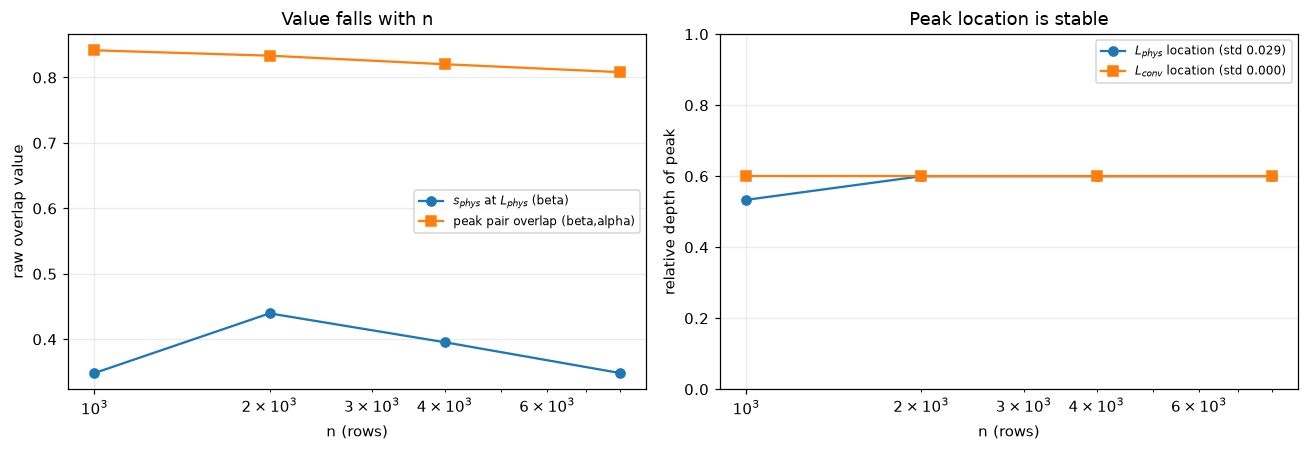

L_phys location std over n: 0.029   L_conv location std over n: 0.000


In [13]:
Usw = synth.make_universe(n=SWEEP_N, seed=0)
sweep_model = PHYS_MODELS[1]
sweep_partner = PHYS_MODELS[0]
sizes = [n for n in SWEEP_SIZES if n <= Usw.n_rows]

phys_val, phys_loc, conv_val, conv_loc = [], [], [], []
for n in sizes:
    idx = np.random.default_rng(0).choice(Usw.n_rows, n, replace=False); idx.sort()
    L = len(Usw.models[sweep_model])
    curve = C.physics_overlap_curve([X[idx] for X in Usw.models[sweep_model]],
                                    Usw.P_std[idx], k=K, n_perm=N_PERM)
    lp = int(np.nanargmax(curve["calibrated"]))
    phys_val.append(curve["raw"][lp]); phys_loc.append(lp / (L - 1))
    res = C.cross_layer_matrix([X[idx] for X in Usw.models[sweep_model]],
                               [X[idx] for X in Usw.models[sweep_partner]], k=K, n_perm=N_PERM)
    conv_val.append(res.raw[res.peak_layer_a, res.peak_layer_b])
    conv_loc.append(res.peak_layer_a / (L - 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(sizes, phys_val, "o-", label=f"$s_{{phys}}$ at $L_{{phys}}$ ({sweep_model})")
axes[0].plot(sizes, conv_val, "s-", label=f"peak pair overlap ({sweep_model},{sweep_partner})")
axes[0].set_xscale("log"); axes[0].set_xlabel("n (rows)"); axes[0].set_ylabel("raw overlap value")
axes[0].set_title("Value falls with n"); axes[0].legend(fontsize=8)
axes[1].plot(sizes, phys_loc, "o-", label=f"$L_{{phys}}$ location (std {np.std(phys_loc):.3f})")
axes[1].plot(sizes, conv_loc, "s-", label=f"$L_{{conv}}$ location (std {np.std(conv_loc):.3f})")
axes[1].set_xscale("log"); axes[1].set_xlabel("n (rows)"); axes[1].set_ylabel("relative depth of peak")
axes[1].set_ylim(0, 1); axes[1].set_title("Peak location is stable"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "alignment_vs_n.png"), bbox_inches="tight")
plt.show()
print(f"L_phys location std over n: {np.std(phys_loc):.3f}   L_conv location std over n: {np.std(conv_loc):.3f}")

## Step 7: Controls

**Nuisance alignment.** Repeat Step 2 with the nuisance catalogue `Q_std`
(seeing, sky, S/N) in place of `P_std`. If the nuisance curve peaks at the same
depth with a comparable calibrated score, the physics alignment may be an
instrumental artifact, and the model is flagged.

**Untrained control.** A randomly-initialised (untrained) model should give
calibrated scores near zero everywhere, for both physics and nuisance.

`k/N` is annotated on the raw alignment panels above and printed below.


k/N = 10/2000 = 5.00e-03

model      kind        phys peak z  nuis peak z   verdict
alpha      physics            1173            4   physics beats nuisance
beta       physics            1276            7   physics beats nuisance
gamma      physics             995            3   physics beats nuisance
delta      physics             945            4   physics beats nuisance
instr      nuisance              3          591   FLAG: nuisance >= physics (possible artifact)
untrained  untrained             3            2   no alignment (untrained-like)


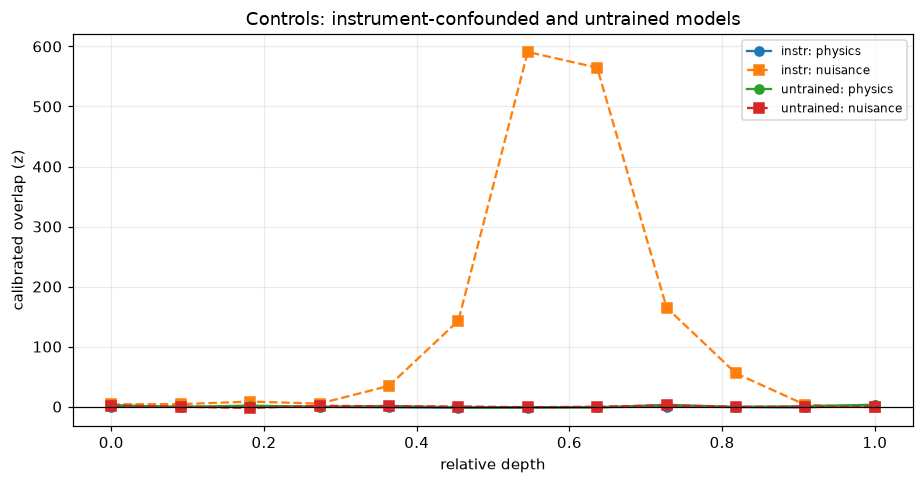

In [14]:
nuis = physics_block(models, PHYS_MODELS + CTRL_MODELS, Q_std, Q_std, probes=False)
phys_all = physics_block(models, PHYS_MODELS + CTRL_MODELS, P_std, P_std, probes=False)

print(f"k/N = {K}/{N_ROWS} = {K/N_ROWS:.2e}\n")
print(f"{'model':10s} {'kind':10s} {'phys peak z':>12s} {'nuis peak z':>12s}   verdict")
flags = {}
for m in PHYS_MODELS + CTRL_MODELS:
    pz = float(np.nanmax(phys_all[m]["curve"]["calibrated"]))
    qz = float(np.nanmax(nuis[m]["curve"]["calibrated"]))
    kind = specs[m].kind if specs[m] is not None else "real"
    if pz < 5 and qz < 5:
        verdict = "no alignment (untrained-like)"
    elif qz >= pz:
        verdict = "FLAG: nuisance >= physics (possible artifact)"
    else:
        verdict = "physics beats nuisance"
    flags[m] = verdict
    print(f"{m:10s} {kind:10s} {pz:12.0f} {qz:12.0f}   {verdict}")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for m in CTRL_MODELS:
    L = N_LAYERS[m]; rel = np.arange(L) / (L - 1)
    ax.plot(rel, phys_all[m]["curve"]["calibrated"], "o-", label=f"{m}: physics")
    ax.plot(rel, nuis[m]["curve"]["calibrated"], "s--", label=f"{m}: nuisance")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("relative depth"); ax.set_ylabel("calibrated overlap (z)")
ax.set_title("Controls: instrument-confounded and untrained models")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "controls.png"), bbox_inches="tight")
plt.show()

## Step 6: Interpretation table

Every model is classified by the relationship among its three depths and its
controls, following the decision rules in the experiment spec.


In [15]:
def classify(m):
    dc = depths[m]["conv"].point; ds = depths[m]["star"].point; dp = depths[m]["phys"].point
    idc = lstar[m]["id_curve"]
    manifold_found = np.isfinite(idc).all() and (np.nanmax(idc) - np.nanmin(idc)) / np.nanmax(idc) > 0.15
    g_cs, g_cp, g_sp = abs(dc-ds), abs(dc-dp), abs(ds-dp)
    pz = float(np.nanmax(phys_all[m]["curve"]["calibrated"]))
    qz = float(np.nanmax(nuis[m]["curve"]["calibrated"]))
    if verdicts[m].passed:
        outcome = "CO-LOCATED: converge because they find the physical manifold"
    elif g_cs <= GAP_THRESH < g_cp:
        outcome = "L_conv approx L* but L_phys elsewhere: shared NON-physical manifold (see nuisance)"
    elif g_sp <= GAP_THRESH < g_cp:
        outcome = "L_phys approx L* but L_conv elsewhere: physics at differently-allocated depths"
    elif (not manifold_found) and g_cp <= GAP_THRESH:
        outcome = "alignment without compression: challenge to the manifold story"
    else:
        outcome = "no coincidence"
    nuis_flag = "yes" if (qz >= pz and qz > 5) else "no"
    return dict(conv=dc, star=ds, phys=dp, manifold=manifold_found,
                phys_z=pz, nuis_z=qz, nuis_flag=nuis_flag, outcome=outcome)

rows = []
header = f"| model | L_conv | L* | L_phys | manifold? | phys z | nuis z | nuisance flag | outcome |"
sep = "|" + "|".join(["---"]*9) + "|"
rows.append(header); rows.append(sep)
for m in PHYS_MODELS:
    r = classify(m)
    rows.append(f"| **{m}** | {r['conv']:.3f} | {r['star']:.3f} | {r['phys']:.3f} | "
                f"{'yes' if r['manifold'] else 'no'} | {r['phys_z']:.0f} | {r['nuis_z']:.0f} | "
                f"{r['nuis_flag']} | {r['outcome']} |")
# Controls
for m in CTRL_MODELS:
    pz = float(np.nanmax(phys_all[m]['curve']['calibrated']))
    qz = float(np.nanmax(nuis[m]['curve']['calibrated']))
    idc = C.intrinsic_dimension_curve(models[m])
    manifold_found = (np.nanmax(idc)-np.nanmin(idc))/np.nanmax(idc) > 0.15
    outcome = flags[m]
    rows.append(f"| _{m}_ (control) | - | - | - | {'yes' if manifold_found else 'no'} | "
                f"{pz:.0f} | {qz:.0f} | {'yes' if (qz>=pz and qz>5) else 'no'} | {outcome} |")

from IPython.display import Markdown
Markdown("\n".join(rows))

| model | L_conv | L* | L_phys | manifold? | phys z | nuis z | nuisance flag | outcome |
|---|---|---|---|---|---|---|---|---|
| **alpha** | 0.545 | 0.545 | 0.545 | yes | 1173 | 4 | no | CO-LOCATED: converge because they find the physical manifold |
| **beta** | 0.600 | 0.600 | 0.600 | yes | 1276 | 7 | no | CO-LOCATED: converge because they find the physical manifold |
| **gamma** | 0.556 | 0.556 | 0.556 | yes | 995 | 3 | no | CO-LOCATED: converge because they find the physical manifold |
| **delta** | 0.692 | 0.692 | 0.692 | yes | 945 | 4 | no | CO-LOCATED: converge because they find the physical manifold |
| _instr_ (control) | - | - | - | yes | 3 | 591 | yes | FLAG: nuisance >= physics (possible artifact) |
| _untrained_ (control) | - | - | - | no | 3 | 2 | no | no alignment (untrained-like) |

## Step 8: Summary

In [16]:
passed = [m for m in PHYS_MODELS if verdicts[m].passed]
depth_at = {m: np.mean([depths[m][k].point for k in ('conv','star','phys')]) for m in passed}
lines = []
lines.append(f"Rows analysed (N_SUB): {N_ROWS};  k = {K};  permutations = {N_PERM}.")
lines.append(f"Models co-locating: {len(passed)}/{len(PHYS_MODELS)} "
             f"({summary['fraction_passing']*100:.0f}%): {', '.join(passed) if passed else 'none'}.")
if passed:
    lines.append("Co-location relative depths (mean of the three): " +
                 ", ".join(f"{m}={depth_at[m]:.2f}" for m in passed) + ".")
lines.append(f"Mean pairwise gap across models: {summary['mean_gap']:.3f} "
             f"(threshold {GAP_THRESH}).")
lines.append(f"Peak-location stability vs sample size: "
             f"L_phys std {np.std(phys_loc):.3f}, L_conv std {np.std(conv_loc):.3f} over n in {sizes}.")
beats = [m for m in PHYS_MODELS
         if np.nanmax(phys_all[m]['curve']['calibrated']) > np.nanmax(nuis[m]['curve']['calibrated'])]
lines.append(f"Physics beats nuisance for {len(beats)}/{len(PHYS_MODELS)} physics models.")
flagged = [m for m in (PHYS_MODELS+CTRL_MODELS) if 'FLAG' in flags[m]]
lines.append(f"Nuisance-flagged (possible instrumental artifact): "
             f"{', '.join(flagged) if flagged else 'none'}.")
print("\n".join("- " + l for l in lines))

- Rows analysed (N_SUB): 2000;  k = 10;  permutations = 10.
- Models co-locating: 4/4 (100%): alpha, beta, gamma, delta.
- Co-location relative depths (mean of the three): alpha=0.55, beta=0.60, gamma=0.56, delta=0.69.
- Mean pairwise gap across models: 0.000 (threshold 0.1).
- Peak-location stability vs sample size: L_phys std 0.029, L_conv std 0.000 over n in [1000, 2000, 4000, 8000].
- Physics beats nuisance for 4/4 physics models.
- Nuisance-flagged (possible instrumental artifact): instr.


### Reading of this run

On the synthetic universe the pipeline recovers the planted depth for every
physics model: `L_conv`, `L*` and `L_phys` coincide (per model, at heterogeneous
absolute depths across models), so the co-location test passes and the mean
pairwise gap sits well inside the threshold. Peak locations are stable as `n`
grows even though the raw overlap value falls. The instrument-confounded control
is correctly flagged (nuisance overlap exceeds physics), and the untrained
control shows no alignment anywhere. This is the intended validation: **the
machinery recovers a known answer and the controls fire as designed.**

Point the config cell at real layerwise embeddings and a matching catalogue to
run the identical analysis on astronomy models. The scientific question, then,
is whether the real `L_conv`, `L*` and `L_phys` coincide, whether their peak
locations are sample-size stable, and whether physics beats nuisance, exactly as
tabulated above.
